# HAM10000: Lesion-Safe Train / Validation / Test Split (v2)

## Protocol locked for the current project

- Dataset: HAM10000 (10,015 images, 7,470 unique lesions, 1,956 multi-image lesions)
- Working task: 7-class skin lesion classification
- Split unit: `lesion_id`
- Split rule: 70% / 15% / 15% of lesions, stratified by `dx`, `random_state=42`
- No other adjustment is applied. Image counts per split are an outcome of the lesion split.
- Required leakage evidence:

```text
Train intersect Validation = 0
Train intersect Test = 0
Validation intersect Test = 0
```

### What this notebook proves

1. Multiple HAM10000 images can belong to the same `lesion_id`.
2. Lesions are the unit being split.
3. Every image inherits the split of its lesion.
4. Whole-lesion assignments remain isolated across train/validation/test.
5. The resulting manifest is saved, fingerprinted and frozen for all later training/evaluation.

### Change log

- **v2:** removed the v1 "whole-lesion rebalance" step. In v1, lesions were swapped between train and test only to reach image totals (7,002 / 1,532 / 1,481) that had no methodological justification. v2 uses the plain stratified lesion split. The validation set is identical to v1, 12 lesions (33 images) differ between train and test.

In [1]:
# Core imports and reproducibility settings
from pathlib import Path
import hashlib
import json
import os
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Point this to the original HAM10000 metadata file, or set HAM10000_METADATA_PATH.
METADATA_PATH = Path(
    os.getenv("HAM10000_METADATA_PATH", "../dataset/HAM10000_metadata.csv")
)
OUTPUT_DIR = Path(os.getenv("HAM10000_SPLIT_OUTPUT_DIR", "output-d.u"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test"]
TARGET_LESION_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

CLASS_LABELS = {
    "nv": "melanocytic nevi",
    "mel": "melanoma",
    "bkl": "benign keratosis-like lesions",
    "bcc": "basal cell carcinoma",
    "akiec": "actinic keratoses / intraepidermal carcinoma",
    "vasc": "vascular lesions",
    "df": "dermatofibroma",
}

# Output files (v2). The v1 files are kept only in an archive folder.
MANIFEST_PATH = OUTPUT_DIR / "HAM10000_lesion_split_seed42_v2.csv"
SUMMARY_PATH = OUTPUT_DIR / "HAM10000_lesion_split_summary_seed42_v2.csv"
CLASS_BY_SPLIT_PATH = OUTPUT_DIR / "HAM10000_class_by_split_seed42_v2.csv"
CHECKS_PATH = OUTPUT_DIR / "HAM10000_lesion_split_checks_seed42_v2.json"
CLASS_COUNTS_PATH = OUTPUT_DIR / "HAM10000_ground_truth_class_counts.csv"
FIGURE_PATH = OUTPUT_DIR / "image_counts_per_split_v2.png"

# Fingerprint of the frozen v2 manifest (see Section 9).
# SHA-256 of [image_id, lesion_id, dx, split] sorted by image_id, CSV without
# index, "\n" line endings -> identical on Windows, macOS, Linux and Colab.
FROZEN_MANIFEST_SHA256 = "bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7"

MANIFEST_COLUMNS = ["image_id", "lesion_id", "dx", "split"]


def manifest_fingerprint(frame: pd.DataFrame) -> str:
    """OS-independent SHA-256 of the manifest content."""
    canonical = (
        frame[MANIFEST_COLUMNS]
        .sort_values("image_id")
        .to_csv(index=False, lineterminator="\n")
    )
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
}
print(json.dumps(ENVIRONMENT, indent=2))

{
  "python": "3.14.3",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy": "2.4.3",
  "pandas": "2.3.3",
  "scikit-learn": "1.8.0"
}


## 1. Load and validate HAM10000 metadata

In [2]:
if not METADATA_PATH.exists():
    # Helpful path hints without scanning the whole filesystem.
    candidates = [
        Path("HAM10000_metadata.csv"),
        Path("/content/HAM10000_metadata.csv"),
        Path("/content/drive/MyDrive/HAM10000/HAM10000_metadata.csv"),
        Path("/content/drive/MyDrive/HAM10000/HAM10000/HAM10000_metadata.csv"),
    ]
    existing = [p for p in candidates if p.exists()]
    if existing:
        METADATA_PATH = existing[0]
    else:
        raise FileNotFoundError(
            f"Could not find HAM10000_metadata.csv. "
            f"Set METADATA_PATH to the actual file path. Checked: {candidates}"
        )

df = pd.read_csv(METADATA_PATH)

REQUIRED_COLUMNS = {"image_id", "lesion_id", "dx"}
missing = REQUIRED_COLUMNS - set(df.columns)
assert not missing, f"Missing required columns: {sorted(missing)}"

df = df.copy()
df["image_id"] = df["image_id"].astype(str)
df["lesion_id"] = df["lesion_id"].astype(str)
df["dx"] = df["dx"].astype(str).str.lower()

print(f"Metadata path: {METADATA_PATH}")
print(f"Rows (images): {len(df):,}")
print(f"Unique image_id: {df['image_id'].nunique():,}")
print(f"Unique lesion_id: {df['lesion_id'].nunique():,}")
display(df.head())

# Dataset facts from the HAM10000 release (Tschandl et al., 2018) and the project audit.
assert len(df) == 10015, f"Expected 10,015 rows, got {len(df):,}"
assert df["image_id"].nunique() == 10015, "image_id must be unique"
assert df["lesion_id"].nunique() == 7470, "Expected 7,470 unique lesions"

Metadata path: ..\dataset\HAM10000_metadata.csv
Rows (images): 10,015
Unique image_id: 10,015
Unique lesion_id: 7,470


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


## 2. Demonstrate that multiple images can belong to one lesion

In [3]:
images_per_lesion = (
    df.groupby("lesion_id")
      .size()
      .rename("image_count")
      .sort_values(ascending=False)
)

multi_image_lesions = images_per_lesion[images_per_lesion > 1]

print(f"Lesions with >= 2 images: {len(multi_image_lesions):,}")
assert len(multi_image_lesions) == 1956, (
    f"Expected 1,956 multi-image lesions, got {len(multi_image_lesions):,}"
)

display(
    df[df["lesion_id"].isin(multi_image_lesions.index)]
      .sort_values(["lesion_id", "image_id"])
      [["image_id", "lesion_id", "dx"]]
      .head(20)
)

display(
    multi_image_lesions.rename_axis("lesion_id").reset_index()
        .head(15)
)

Lesions with >= 2 images: 1,956


,image_id,lesion_id,dx
9188,ISIC_0025346,HAM_0000000,nv
9187,ISIC_0028498,HAM_0000000,nv
1661,ISIC_0032622,HAM_0000002,mel
1660,ISIC_0033848,HAM_0000002,mel
1662,ISIC_0034246,HAM_0000002,mel
9900,ISIC_0024579,HAM_0000005,akiec
9898,ISIC_0025577,HAM_0000005,akiec
9901,ISIC_0029638,HAM_0000005,akiec
9899,ISIC_0030591,HAM_0000005,akiec
1517,ISIC_0032187,HAM_0000006,mel


,lesion_id,image_count
0,HAM_0000835,6
1,HAM_0005263,6
2,HAM_0003789,6
3,HAM_0001863,6
4,HAM_0007427,5
5,HAM_0000893,5
6,HAM_0007367,5
7,HAM_0007343,5
8,HAM_0002364,5
9,HAM_0006469,4


### Why this matters

The rows above show that one `lesion_id` can correspond to multiple image records.

Therefore, splitting individual image rows independently can place related images from the same lesion into different partitions. The safe unit for this protocol is the lesion group.

## 3. Build one row per lesion

In [4]:
# Each lesion must have exactly one ground-truth diagnostic class in this metadata.
dx_per_lesion = df.groupby("lesion_id")["dx"].nunique()
bad_lesions = dx_per_lesion[dx_per_lesion != 1]
assert bad_lesions.empty, (
    "Some lesion_id values have multiple dx labels; inspect the metadata before splitting."
)

lesion_df = (
    df.groupby("lesion_id", as_index=False)
      .agg(
          dx=("dx", "first"),
          n_images=("image_id", "size"),
      )
)

print(f"Lesion-level rows: {len(lesion_df):,}")
display(lesion_df.head())

assert len(lesion_df) == 7470
assert lesion_df["lesion_id"].is_unique

Lesion-level rows: 7,470


,lesion_id,dx,n_images
0,HAM_0000000,nv,2
1,HAM_0000001,bkl,1
2,HAM_0000002,mel,3
3,HAM_0000003,nv,1
4,HAM_0000004,nv,1


## 4. Split lesions 70 / 15 / 15

`train_test_split(..., stratify=dx, random_state=42)` is applied to the lesion table:

1. 70% of lesions -> train, 30% -> temporary pool
2. 50% of the pool -> validation, 50% -> test

In [5]:
train_lesions, temp_lesions = train_test_split(
    lesion_df,
    test_size=0.30,
    stratify=lesion_df["dx"],
    random_state=RANDOM_SEED,
)

val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["dx"],
    random_state=RANDOM_SEED,
)

lesion_assignments = pd.concat(
    [
        train_lesions.assign(split="train"),
        val_lesions.assign(split="val"),
        test_lesions.assign(split="test"),
    ],
    ignore_index=True,
)

# Every lesion is assigned exactly once.
assert len(lesion_assignments) == len(lesion_df)
assert not lesion_assignments["lesion_id"].duplicated().any()

lesion_counts = lesion_assignments["split"].value_counts().reindex(SPLITS)
lesion_ratios = (lesion_counts / lesion_counts.sum()).round(4)
display(pd.DataFrame({"lesions": lesion_counts, "lesion_ratio": lesion_ratios}))

# Ratios must match the rule up to rounding of whole lesions.
for split, target in TARGET_LESION_RATIOS.items():
    assert abs(lesion_ratios[split] - target) < 0.001, (split, lesion_ratios[split])

,lesions,lesion_ratio
split,,
train,5229,0.7000
val,1120,0.1499
test,1121,0.1501


## 5. Propagate lesion assignments back to the 10,015 image rows

In [6]:
manifest = df.merge(
    lesion_assignments[["lesion_id", "split"]],
    on="lesion_id",
    how="left",
    validate="many_to_one",
)

assert len(manifest) == len(df)
assert manifest["split"].notna().all()

# Every image appears exactly once, and every image inherits one split from its lesion.
assert manifest["image_id"].is_unique
assert manifest["lesion_id"].nunique() == 7470

display(
    manifest[["image_id", "lesion_id", "dx", "split"]]
        .head(15)
)

,image_id,lesion_id,dx,split
0,ISIC_0027419,HAM_0000118,bkl,train
1,ISIC_0025030,HAM_0000118,bkl,train
2,ISIC_0026769,HAM_0002730,bkl,train
3,ISIC_0025661,HAM_0002730,bkl,train
4,ISIC_0031633,HAM_0001466,bkl,train
5,ISIC_0027850,HAM_0001466,bkl,train
6,ISIC_0029176,HAM_0002761,bkl,test
7,ISIC_0029068,HAM_0002761,bkl,test
8,ISIC_0025837,HAM_0005132,bkl,test
9,ISIC_0025209,HAM_0005132,bkl,test


## 6. Inspect split sizes and class distribution

In [7]:
split_summary = (
    manifest.groupby("split")
        .agg(images=("image_id", "size"), lesions=("lesion_id", "nunique"))
        .reindex(SPLITS)
)
split_summary["lesion_ratio_pct"] = (
    100 * split_summary["lesions"] / split_summary["lesions"].sum()
).round(2)
split_summary["image_ratio_pct"] = (
    100 * split_summary["images"] / split_summary["images"].sum()
).round(2)
display(split_summary)

assert int(split_summary["images"].sum()) == len(df)
assert int(split_summary["lesions"].sum()) == df["lesion_id"].nunique()

class_by_split = (
    pd.crosstab(manifest["split"], manifest["dx"])
      .reindex(index=SPLITS, columns=CLASS_LABELS.keys(), fill_value=0)
)
print("Images per split x diagnostic class:")
display(class_by_split)

# Every class must appear in every split.
assert (class_by_split > 0).all().all()

,images,lesions,lesion_ratio_pct,image_ratio_pct
split,,,,
train,6981,5229,70.00,69.71
val,1532,1120,14.99,15.30
test,1502,1121,15.01,15.00


Images per split x diagnostic class:


dx,nv,mel,bkl,bcc,akiec,vasc,df
split,,,,,,,
train,4683,773,772,361,222,99,71
val,1018,173,160,82,53,22,24
test,1004,167,167,71,52,21,20


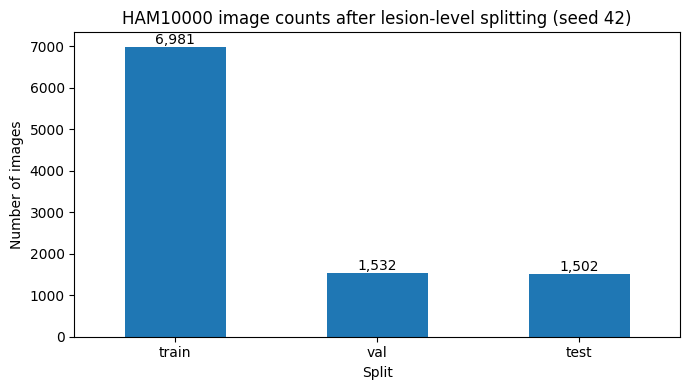

In [8]:
ax = split_summary["images"].plot(kind="bar", figsize=(7, 4))
ax.set_title("HAM10000 image counts after lesion-level splitting (seed 42)")
ax.set_xlabel("Split")
ax.set_ylabel("Number of images")
for i, v in enumerate(split_summary["images"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_PATH, dpi=300)
plt.show()

## 7. Evidence

### 7.1 Lesion-safe split

In [9]:
train_lesion_ids = set(manifest.loc[manifest["split"] == "train", "lesion_id"])
val_lesion_ids = set(manifest.loc[manifest["split"] == "val", "lesion_id"])
test_lesion_ids = set(manifest.loc[manifest["split"] == "test", "lesion_id"])

train_val_overlap = train_lesion_ids & val_lesion_ids
train_test_overlap = train_lesion_ids & test_lesion_ids
val_test_overlap = val_lesion_ids & test_lesion_ids

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print(f"Train join Validation = {len(train_val_overlap)}")
print(f"Train join Test = {len(train_test_overlap)}")
print(f"Validation join Test = {len(val_test_overlap)}")

Train join Validation = 0
Train join Test = 0
Validation join Test = 0


### Interpretation

The three intersection checks are performed on `lesion_id` sets, not on image IDs.

Therefore, a multi-image lesion cannot contribute an image to one partition and another image to a different partition under this manifest.

### 7.2 Prove the seven classes and their image counts from ground-truth labels

The seven diagnostic classes are not hard-coded as the source of the result. The class list and counts below are derived directly from the ground-truth `dx` column in `HAM10000_metadata.csv`.

The mapping from the short `dx` code to the full diagnostic class name is only for presentation, the counts themselves come from the ground-truth labels.

In [10]:
# Ground-truth evidence: derive the seven classes and image counts directly from df["dx"].
ground_truth_counts = (
    df["dx"]
    .value_counts()
    .rename_axis("dx")
    .reset_index(name="images")
)

ground_truth_counts["class_name"] = ground_truth_counts["dx"].map(CLASS_LABELS)

ground_truth_counts = ground_truth_counts[["dx", "class_name", "images"]]

display(ground_truth_counts)

# These are the seven labels observed in the ground-truth metadata.
expected_class_codes = set(CLASS_LABELS.keys())
observed_class_codes = set(ground_truth_counts["dx"])

assert observed_class_codes == expected_class_codes, (
    f"Unexpected ground-truth class codes: {sorted(observed_class_codes)}"
)
assert len(observed_class_codes) == 7
assert int(ground_truth_counts["images"].sum()) == 10015

# Reconciliation against the project's audited dataset counts.
# The observed values above are still produced from df["dx"].value_counts().
expected_ground_truth_counts = {
    "nv": 6705,
    "mel": 1113,
    "bkl": 1099,
    "bcc": 514,
    "akiec": 327,
    "vasc": 142,
    "df": 115,
}

observed_ground_truth_counts = (
    ground_truth_counts.set_index("dx")["images"].to_dict()
)

assert observed_ground_truth_counts == expected_ground_truth_counts

print("Ground-truth class codes:", sorted(observed_class_codes))
print("Ground-truth class count total:", int(ground_truth_counts["images"].sum()))
print("PASS - seven classes and all image counts are reproduced directly from the ground-truth dx labels.")

,dx,class_name,images
0,nv,melanocytic nevi,6705
1,mel,melanoma,1113
2,bkl,benign keratosis-like lesions,1099
3,bcc,basal cell carcinoma,514
4,akiec,actinic keratoses / intraepidermal carcinoma,327
5,vasc,vascular lesions,142
6,df,dermatofibroma,115


Ground-truth class codes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Ground-truth class count total: 10015
PASS - seven classes and all image counts are reproduced directly from the ground-truth dx labels.


**Interpretation**

Ground-truth labels define the seven classes. Counting those labels gives the number of images in each class across the whole dataset (all splits combined).

## 8. Final consistency checks

In [11]:
assert manifest["image_id"].nunique() == len(df)
assert manifest["image_id"].is_unique
assert manifest["split"].isin(SPLITS).all()

# Every lesion is wholly assigned to exactly one split.
assert (manifest.groupby("lesion_id")["split"].nunique() == 1).all()

print("PASS - all final integrity checks succeeded.")

PASS - all final integrity checks succeeded.


## 9. Save and freeze the split manifest

The first run on a clean folder writes the manifest. Every later run regenerates the split, checks that it is identical to the frozen fingerprint, and never overwrites the saved file. Training and evaluation code must load `HAM10000_lesion_split_seed42_v2.csv`.

In [12]:
manifest_to_save = manifest[MANIFEST_COLUMNS].sort_values(["split", "image_id"])
generated_sha256 = manifest_fingerprint(manifest_to_save)
print(f"Generated manifest SHA-256: {generated_sha256}")

if FROZEN_MANIFEST_SHA256 != "PENDING" and generated_sha256 != FROZEN_MANIFEST_SHA256:
    raise RuntimeError(
        "The generated split differs from the frozen v2 manifest. "
        "This usually means a different library version (see ENVIRONMENT). "
        "Do not overwrite the project manifest; load the saved CSV instead."
    )

if MANIFEST_PATH.exists():
    saved_sha256 = manifest_fingerprint(pd.read_csv(MANIFEST_PATH))
    assert saved_sha256 == generated_sha256, (
        f"Saved manifest at {MANIFEST_PATH} does not match the generated split "
        f"(SHA-256 {saved_sha256}). Restore it from version control."
    )
    print("Saved manifest matches; not rewritten.")
else:
    manifest_to_save.to_csv(MANIFEST_PATH, index=False, lineterminator="\n")
    print(f"Manifest written: {MANIFEST_PATH}")

split_summary.reset_index().to_csv(SUMMARY_PATH, index=False, lineterminator="\n")
class_by_split.reset_index().to_csv(CLASS_BY_SPLIT_PATH, index=False, lineterminator="\n")
ground_truth_counts.to_csv(CLASS_COUNTS_PATH, index=False, lineterminator="\n")

checks = {
    "protocol_version": "v2",
    "metadata_rows": int(len(df)),
    "unique_image_ids": int(df["image_id"].nunique()),
    "unique_lesions": int(df["lesion_id"].nunique()),
    "multi_image_lesions": int(len(multi_image_lesions)),
    "random_seed": RANDOM_SEED,
    "split_unit": "lesion_id",
    "split_rule": "train_test_split on lesions, stratify=dx, 70/15/15, no post-hoc adjustment",
    "target_lesion_ratio": TARGET_LESION_RATIOS,
    "image_counts": {s: int(split_summary.loc[s, "images"]) for s in SPLITS},
    "lesion_counts": {s: int(split_summary.loc[s, "lesions"]) for s in SPLITS},
    "class_by_split": {s: {k: int(v) for k, v in class_by_split.loc[s].items()} for s in SPLITS},
    "ground_truth_class_counts": observed_ground_truth_counts,
    "lesion_overlap": {
        "train_val": len(train_val_overlap),
        "train_test": len(train_test_overlap),
        "val_test": len(val_test_overlap),
    },
    "manifest_sha256": generated_sha256,
    "manifest_sha256_definition": (
        "SHA-256 of [image_id, lesion_id, dx, split] sorted by image_id, "
        "CSV without index, LF line endings"
    ),
    "environment": ENVIRONMENT,
}
CHECKS_PATH.write_text(json.dumps(checks, indent=2), encoding="utf-8")

for p in [MANIFEST_PATH, SUMMARY_PATH, CLASS_BY_SPLIT_PATH, CHECKS_PATH, CLASS_COUNTS_PATH, FIGURE_PATH]:
    print(f"Saved: {p.resolve()}")

Generated manifest SHA-256: bda53d198ff403653548b8f072116e78350067417ddf41ec3e342f034bf464d7
Manifest written: output-d.u\HAM10000_lesion_split_seed42_v2.csv
Saved: D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_lesion_split_seed42_v2.csv
Saved: D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_lesion_split_summary_seed42_v2.csv
Saved: D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_class_by_split_seed42_v2.csv
Saved: D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_lesion_split_checks_seed42_v2.json
Saved: D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\HAM10000_ground_truth_class_counts.csv
Saved: D:\AI\Kì 5\DSR301m\Skin-Lesion-Classification\data-understanding\output-d.u\image_counts_per_split_v2.png
